In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/pneumonia_dataset_final.csv")

X = df.drop(columns=["hadm_id", "pneumonia_label"])
y = df["pneumonia_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,      # 20% held out as the test set
    stratify=y,          # keep the 75/25 class ratio in both parts
    random_state=42,     # same split every time you run it
)

print("Train:", X_train.shape, y_train.value_counts().to_dict())
print("Test: ", X_test.shape,  y_test.value_counts().to_dict())

# Save them so every later experiment uses the exact same split
X_train.assign(pneumonia_label=y_train).to_csv("data/train.csv", index=False)
X_test.assign(pneumonia_label=y_test).to_csv("data/test.csv", index=False)

Train: (6117, 38) {1: 4575, 0: 1542}
Test:  (1530, 38) {1: 1144, 0: 386}


In [2]:
import pandas as pd

def clean(df):
    df = df.copy()

    # 1. Constant column (100 for everyone): no information
    df = df.drop(columns=["spo2_max"])

    # 2. Trend columns are a calculation bug (HR, RR and SpO2 trends are near-identical)
    trend_cols = [c for c in df.columns if c.endswith("_trend")]
    df = df.drop(columns=trend_cols)

    # 3. SpO2 can't be above 100%
    df["spo2_mean"] = df["spo2_mean"].clip(upper=100)

    # 4. Clipping left some means outside their own min/max: pull them back inside
    for v in ["heart_rate", "respiratory_rate", "sbp", "spo2", "temperature"]:
        df[f"{v}_mean"] = df[f"{v}_mean"].clip(df[f"{v}_min"], df[f"{v}_max"] if f"{v}_max" in df else None)

    return df

train = clean(pd.read_csv("data/train.csv"))
test  = clean(pd.read_csv("data/test.csv"))

print(train.shape, test.shape)   # expect 33 columns each (32 features + label)
train.to_csv("data/train_clean.csv", index=False)
test.to_csv("data/test_clean.csv", index=False)

(6117, 33) (1530, 33)


In [3]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

train = pd.read_csv("data/train_clean.csv")
X = train.drop(columns=["pneumonia_label"])
y = train["pneumonia_label"]

model = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000)),
])

# Your 5 target metrics
scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "balanced_acc": "balanced_accuracy",
    "pneumonia_recall": "recall",                                  # sensitivity
    "control_recall": make_scorer(recall_score, pos_label=0),      # specificity
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
res = cross_validate(model, X, y, cv=cv, scoring=scoring)

for name in scoring:
    s = res[f"test_{name}"]
    print(f"{name:18s} {s.mean()*100:5.1f}%  (± {s.std()*100:.1f})")

roc_auc             79.7%  (± 1.7)
accuracy            78.9%  (± 0.8)
balanced_acc        66.5%  (± 1.0)
pneumonia_recall    91.5%  (± 1.2)
control_recall      41.4%  (± 2.0)


In [4]:
import pandas as pd
from imblearn.pipeline import Pipeline          # imblearn's Pipeline, not sklearn's
from imblearn.over_sampling import SMOTENC
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

train = pd.read_csv("data/train_clean.csv")
X = train.drop(columns=["pneumonia_label"])
y = train["pneumonia_label"]

# 0/1 columns, so SMOTENC keeps them as 0 or 1 instead of 0.37
binary_cols = [c for c in X.columns if X[c].nunique() == 2]
binary_idx = [X.columns.get_loc(c) for c in binary_cols]

models = {
    "baseline": Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000)),
    ]),
    "class_weight": Pipeline([                   # no fake rows, just weights controls more
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ]),
    "smotenc": Pipeline([                        # runs on the training folds only
        ("smote", SMOTENC(categorical_features=binary_idx, random_state=42)),
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000)),
    ]),
}

scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "balanced_acc": "balanced_accuracy",
    "pneumonia_recall": "recall",
    "control_recall": make_scorer(recall_score, pos_label=0),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = {}
for name, model in models.items():
    res = cross_validate(model, X, y, cv=cv, scoring=scoring)
    rows[name] = {m: round(res[f"test_{m}"].mean() * 100, 1) for m in scoring}

print(pd.DataFrame(rows).T)

              roc_auc  accuracy  balanced_acc  pneumonia_recall  \
baseline         79.7      78.9          66.5              91.5   
class_weight     79.7      72.3          73.2              71.3   
smotenc          78.1      73.2          71.7              74.8   

              control_recall  
baseline                41.4  
class_weight            75.0  
smotenc                 68.7  


In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier

models = {
    "hgb_weight": HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
    "hgb_smotenc": Pipeline([
        ("smote", SMOTENC(categorical_features=binary_idx, random_state=42)),
        ("clf", HistGradientBoostingClassifier(random_state=42)),
    ]),
    "rf_weight": RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                                        class_weight="balanced", n_jobs=-1, random_state=42),
    "rf_smotenc": Pipeline([
        ("smote", SMOTENC(categorical_features=binary_idx, random_state=42)),
        ("clf", RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                                       n_jobs=-1, random_state=42)),
    ]),
}

In [7]:
import pandas as pd
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

train = pd.read_csv("data/train_clean.csv")
X = train.drop(columns=["pneumonia_label"])
y = train["pneumonia_label"]

binary_cols = [c for c in X.columns if X[c].nunique() == 2]
binary_idx = [X.columns.get_loc(c) for c in binary_cols]

models = {
    "hgb_weight": HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
    "hgb_smotenc": Pipeline([
        ("smote", SMOTENC(categorical_features=binary_idx, random_state=42)),
        ("clf", HistGradientBoostingClassifier(random_state=42)),
    ]),
    "rf_weight": RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                                        class_weight="balanced", n_jobs=-1, random_state=42),
    "rf_smotenc": Pipeline([
        ("smote", SMOTENC(categorical_features=binary_idx, random_state=42)),
        ("clf", RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                                       n_jobs=-1, random_state=42)),
    ]),
}

scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "balanced_acc": "balanced_accuracy",
    "pneumonia_recall": "recall",
    "control_recall": make_scorer(recall_score, pos_label=0),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = {}
for name, model in models.items():
    print("running", name, "...")
    res = cross_validate(model, X, y, cv=cv, scoring=scoring)
    rows[name] = {m: round(res[f"test_{m}"].mean() * 100, 1) for m in scoring}

print(pd.DataFrame(rows).T)

running hgb_weight ...
running hgb_smotenc ...
running rf_weight ...
running rf_smotenc ...
             roc_auc  accuracy  balanced_acc  pneumonia_recall  control_recall
hgb_weight      78.4      76.6          71.6              81.7            61.5
hgb_smotenc     78.1      77.9          69.5              86.5            52.5
rf_weight       80.0      77.6          73.1              82.1            64.1
rf_smotenc      79.6      77.8          72.5              83.3            61.7


In [8]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, balanced_accuracy_score, recall_score

train = pd.read_csv("data/train_clean.csv")
test = pd.read_csv("data/test_clean.csv")
X_train, y_train = train.drop(columns=["pneumonia_label"]), train["pneumonia_label"]
X_test, y_test = test.drop(columns=["pneumonia_label"]), test["pneumonia_label"]

model = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
]).fit(X_train, y_train)

proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"roc_auc          {roc_auc_score(y_test, proba)*100:.1f}%")
print(f"accuracy         {accuracy_score(y_test, pred)*100:.1f}%")
print(f"balanced_acc     {balanced_accuracy_score(y_test, pred)*100:.1f}%")
print(f"pneumonia_recall {recall_score(y_test, pred)*100:.1f}%")
print(f"control_recall   {recall_score(y_test, pred, pos_label=0)*100:.1f}%")

# Which features matter most
coefs = pd.Series(model.named_steps["clf"].coef_[0], index=X_train.columns)
print(coefs.sort_values(key=abs, ascending=False).head(10).round(2))

roc_auc          79.8%
accuracy         72.0%
balanced_acc     72.9%
pneumonia_recall 71.2%
control_recall   74.6%
respiratory_distress     0.64
temperature_max          0.53
respiratory_rate_mean    0.39
temperature_min         -0.36
temperature_std         -0.34
spo2_min                -0.18
respiratory_rate_max     0.18
heart_rate_max           0.16
copd                     0.15
respiratory_rate_std    -0.12
dtype: float64


In [9]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import make_scorer, recall_score, roc_auc_score, balanced_accuracy_score

train = pd.read_csv("data/train_clean.csv")
X = train.drop(columns=["pneumonia_label"])
y = train["pneumonia_label"]

stage1_cols = [
    "heart_rate_max", "respiratory_rate_max", "spo2_min",
    "temperature_max", "sbp_min", "respiratory_distress"
]

stage2_cols = [
    "heart_rate_max", "heart_rate_std", "respiratory_rate_max", "respiratory_rate_mean",
    "sbp_min", "sbp_std", "spo2_min", "spo2_mean", "temperature_max", "temperature_std",
    "respiratory_distress", "hypoxemia", "copd", "heart_failure", "renal"
]

feature_sets = {
    "All 32 features": X.columns.tolist(),
    "Stage 2 (15 features)": stage2_cols,
    "Stage 1 (6 features)": stage1_cols,
}

scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "balanced_acc": "balanced_accuracy",
    "pneumonia_recall": "recall",
    "control_recall": make_scorer(recall_score, pos_label=0),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = {}

for name, cols in feature_sets.items():
    model = Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ])
    res = cross_validate(model, X[cols], y, cv=cv, scoring=scoring)
    rows[name] = {m: round(res[f"test_{m}"].mean() * 100, 1) for m in scoring}

print(pd.DataFrame(rows).T)

                       roc_auc  accuracy  balanced_acc  pneumonia_recall  \
All 32 features           79.7      72.3          73.2              71.3   
Stage 2 (15 features)     79.7      71.9          73.1              70.7   
Stage 1 (6 features)      78.7      70.9          72.6              69.2   

                       control_recall  
All 32 features                  75.0  
Stage 2 (15 features)            75.6  
Stage 1 (6 features)             76.0  


In [10]:
import numpy as np
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import recall_score, balanced_accuracy_score, accuracy_score

stage1_model = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

# Out-of-fold probabilities on the training set (no leakage)
oof_proba = cross_val_predict(
    stage1_model, X[stage1_cols], y, cv=cv, method="predict_proba"
)[:, 1]

# Scan thresholds to find the highest cutoff that achieves >= 90% pneumonia recall
for t in np.linspace(0.05, 0.95, 181):
    preds = (oof_proba >= t).astype(int)
    sens = recall_score(y, preds)
    spec = recall_score(y, preds, pos_label=0)
    if sens >= 0.90:
        best_t, best_sens, best_spec = t, sens, spec
        best_acc = accuracy_score(y, preds)
        best_bal = balanced_accuracy_score(y, preds)

print(f"Stage 1 Threshold:    {best_t:.2f}")
print(f"Pneumonia Recall:     {best_sens*100:.1f}%")
print(f"Control Recall:       {best_spec*100:.1f}%")
print(f"Balanced Accuracy:    {best_bal*100:.1f}%")
print(f"Overall Accuracy:     {best_acc*100:.1f}%")

Stage 1 Threshold:    0.26
Pneumonia Recall:     90.5%
Control Recall:       39.9%
Balanced Accuracy:    65.2%
Overall Accuracy:     77.8%


In [11]:
# 1. Get out-of-fold probabilities for Stage 2 (15 features)
stage2_model = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

oof_proba_s2 = cross_val_predict(
    stage2_model, X[stage2_cols], y, cv=cv, method="predict_proba"
)[:, 1]

# Sequential rule: Flagged by Stage 1 (>= 0.26) AND confirmed by Stage 2 (>= 0.50)
s1_pred = (oof_proba >= 0.26).astype(int)
s2_pred = (oof_proba_s2 >= 0.50).astype(int)
combined_pred = (s1_pred & s2_pred)

print("--- Sequential Two-Stage System (S1 >= 0.26 -> S2 >= 0.50) ---")
print(f"Pneumonia Recall:  {recall_score(y, combined_pred)*100:.1f}%")
print(f"Control Recall:    {recall_score(y, combined_pred, pos_label=0)*100:.1f}%")
print(f"Balanced Accuracy: {balanced_accuracy_score(y, combined_pred)*100:.1f}%")
print(f"Overall Accuracy:  {accuracy_score(y, combined_pred)*100:.1f}%\n")

# 2. Recompute single-feature AUCs strictly on train_clean.csv (fixes report issue)
single_aucs = {}
for col in X.columns:
    auc = roc_auc_score(y, X[col])
    single_aucs[col] = max(auc, 1 - auc)

print("--- Top 10 Single Features (Train Only) ---")
print(pd.Series(single_aucs).sort_values(ascending=False).head(10).round(3))

--- Sequential Two-Stage System (S1 >= 0.26 -> S2 >= 0.50) ---
Pneumonia Recall:  70.7%
Control Recall:    75.6%
Balanced Accuracy: 73.1%
Overall Accuracy:  71.9%

--- Top 10 Single Features (Train Only) ---
respiratory_distress     0.714
respiratory_rate_max     0.690
respiratory_rate_mean    0.677
spo2_min                 0.670
temperature_max          0.650
heart_rate_max           0.647
spo2_std                 0.632
respiratory_rate_std     0.631
hypoxemia                0.625
heart_rate_std           0.616
dtype: float64


=== FINAL TEST SET RESULTS (n=1,530) ===
                           ROC AUC  Accuracy  Balanced Acc  Pneumonia Recall  \
Stage 1 (6 feat, t=0.26)      78.2      77.6          64.9              90.6   
Stage 2 (15 feat, t=0.50)     79.7      71.8          72.4              71.2   
Combined Two-Stage            79.7      71.8          72.4              71.2   

                           Control Recall  
Stage 1 (6 feat, t=0.26)             39.1  
Stage 2 (15 feat, t=0.50)            73.6  
Combined Two-Stage                   73.6  

Stage 2 Test AUC 95% CI:          77.1% – 82.2%
Stage 2 Balanced Acc 95% CI:      69.8% – 75.0%


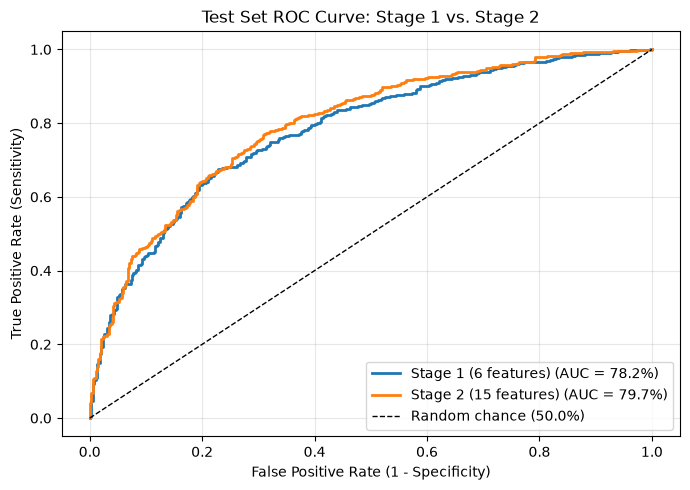

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, accuracy_score, balanced_accuracy_score,
    recall_score, roc_curve
)

train = pd.read_csv("data/train_clean.csv")
test = pd.read_csv("data/test_clean.csv")

X_train, y_train = train.drop(columns=["pneumonia_label"]), train["pneumonia_label"]
X_test, y_test = test.drop(columns=["pneumonia_label"]), test["pneumonia_label"]

# Fit Stage 1 (6 features) and Stage 2 (15 features) on full training set
s1_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
]).fit(X_train[stage1_cols], y_train)

s2_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
]).fit(X_train[stage2_cols], y_train)

# Predict on held-out test set
s1_proba = s1_pipe.predict_proba(X_test[stage1_cols])[:, 1]
s2_proba = s2_pipe.predict_proba(X_test[stage2_cols])[:, 1]

s1_pred = (s1_proba >= 0.26).astype(int)
s2_pred = (s2_proba >= 0.50).astype(int)
two_stage_pred = (s1_pred & s2_pred)

def eval_metrics(y_true, pred, proba=None):
    return {
        "ROC AUC": round(roc_auc_score(y_true, proba) * 100, 1) if proba is not None else "-",
        "Accuracy": round(accuracy_score(y_true, pred) * 100, 1),
        "Balanced Acc": round(balanced_accuracy_score(y_true, pred) * 100, 1),
        "Pneumonia Recall": round(recall_score(y_true, pred) * 100, 1),
        "Control Recall": round(recall_score(y_true, pred, pos_label=0) * 100, 1),
    }

results = pd.DataFrame({
    "Stage 1 (6 feat, t=0.26)": eval_metrics(y_test, s1_pred, s1_proba),
    "Stage 2 (15 feat, t=0.50)": eval_metrics(y_test, s2_pred, s2_proba),
    "Combined Two-Stage": eval_metrics(y_test, two_stage_pred, s2_proba),
}).T

print("=== FINAL TEST SET RESULTS (n=1,530) ===")
print(results)

# 95% Bootstrap Confidence Intervals for Stage 2 on Test Set
rng = np.random.default_rng(42)
boot_aucs, boot_bal = [], []
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    boot_aucs.append(roc_auc_score(y_test.iloc[idx], s2_proba[idx]) * 100)
    boot_bal.append(balanced_accuracy_score(y_test.iloc[idx], s2_pred[idx]) * 100)

print(f"\nStage 2 Test AUC 95% CI:          {np.percentile(boot_aucs, 2.5):.1f}% – {np.percentile(boot_aucs, 97.5):.1f}%")
print(f"Stage 2 Balanced Acc 95% CI:      {np.percentile(boot_bal, 2.5):.1f}% – {np.percentile(boot_bal, 97.5):.1f}%")

# Plot ROC Curves
plt.figure(figsize=(7, 5))
for label, proba in [("Stage 1 (6 features)", s1_proba), ("Stage 2 (15 features)", s2_proba)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val = roc_auc_score(y_test, proba) * 100
    plt.plot(fpr, tpr, lw=2, label=f"{label} (AUC = {auc_val:.1f}%)")

plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random chance (50.0%)")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("Test Set ROC Curve: Stage 1 vs. Stage 2")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
import numpy as np
from sklearn.metrics import roc_auc_score

# Using the boolean arrays from the test set evaluation
s1 = s1_proba >= 0.26
s2 = s2_proba >= 0.50

print(f"Flagged by Stage 1: {s1.mean()*100:.1f}%")
print("Stage 2 positives that Stage 1 missed:", (s2 & ~s1).sum())

# Calculate combined AUC by treating unflagged patients as strict 0s
combined_score = np.where(s1, s2_proba, 0)
print(f"Combined AUC: {roc_auc_score(y_test, combined_score) * 100:.1f}%")

Flagged by Stage 1: 83.1%
Stage 2 positives that Stage 1 missed: 0
Combined AUC: 78.8%


In [18]:
import joblib, numpy as np, pandas as pd

STAGE1_FEATS = ["heart_rate_max", "respiratory_rate_max", "spo2_min", "temperature_max", "sbp_min", "respiratory_distress"]
STAGE2_FEATS = ["heart_rate_max", "heart_rate_std", "respiratory_rate_max", "respiratory_rate_mean",
                "sbp_min", "sbp_std", "spo2_min", "spo2_mean", "temperature_max", "temperature_std",
                "respiratory_distress", "hypoxemia", "copd", "heart_failure", "renal"]

# Fit both models on the full training set (cross_val_predict never fits the originals)
train = pd.read_csv("data/train_clean.csv")
y_train = train["pneumonia_label"]
stage1_model.fit(train[STAGE1_FEATS], y_train)
stage2_model.fit(train[STAGE2_FEATS], y_train)

# Save model + its features + its threshold together, so the app can't mix them up
joblib.dump({"model": stage1_model, "features": STAGE1_FEATS, "threshold": 0.26}, "stage1.joblib")
joblib.dump({"model": stage2_model, "features": STAGE2_FEATS, "threshold": 0.50}, "stage2.joblib")
s1, s2 = joblib.load("stage1.joblib"), joblib.load("stage2.joblib")

VITALS = ["heart_rate", "respiratory_rate", "sbp", "spo2", "temperature"]
FLAGS = ["respiratory_distress", "hypoxemia", "copd", "heart_failure", "renal"]

def assess(readings, flags):
    """readings: {vital: [values...]} from the database; flags: {flag: 0 or 1}"""
    missing = [v for v in VITALS if not readings.get(v)] + [f for f in FLAGS if f not in flags]
    if missing:
        raise ValueError(f"Missing inputs: {missing}")
    f = dict(flags)
    for v in VITALS:
        a = np.asarray(readings[v], dtype=float)
        f[f"{v}_mean"], f[f"{v}_min"], f[f"{v}_max"] = a.mean(), a.min(), a.max()
        f[f"{v}_std"] = a.std(ddof=1) if len(a) > 1 else 0.0
    row = pd.DataFrame([f])
    p1 = s1["model"].predict_proba(row[s1["features"]])[0, 1]
    if p1 < s1["threshold"]:
        return {"stage": 1, "p_stage1": round(p1, 3), "result": "low risk"}
    p2 = s2["model"].predict_proba(row[s2["features"]])[0, 1]
    return {"stage": 2, "p_stage1": round(p1, 3), "p_stage2": round(p2, 3),
            "result": "pneumonia likely" if p2 >= s2["threshold"] else "flagged, not likely"}

# --- Check 1: reloaded models give identical results on the test set ---
test = pd.read_csv("data/test_clean.csv")
same1 = np.allclose(stage1_model.predict_proba(test[STAGE1_FEATS])[:, 1], s1["model"].predict_proba(test[STAGE1_FEATS])[:, 1])
same2 = np.allclose(stage2_model.predict_proba(test[STAGE2_FEATS])[:, 1], s2["model"].predict_proba(test[STAGE2_FEATS])[:, 1])
print("1. Save/reload identical:", same1 and same2)

# --- Check 2: sick vs healthy patient ---
sick = {"heart_rate": [105, 118, 124, 112], "respiratory_rate": [26, 32, 35, 30],
        "sbp": [100, 92, 88, 95], "spo2": [91, 87, 85, 89], "temperature": [100.2, 101.8, 102.4, 101.0]}
healthy = {"heart_rate": [72, 78, 75, 80], "respiratory_rate": [14, 16, 15, 17],
           "sbp": [125, 130, 122, 128], "spo2": [98, 97, 99, 98], "temperature": [98.2, 98.6, 98.4, 98.5]}
print("2. Sick:   ", assess(sick, {"respiratory_distress": 1, "hypoxemia": 1, "copd": 1, "heart_failure": 0, "renal": 0}))
print("   Healthy:", assess(healthy, {"respiratory_distress": 0, "hypoxemia": 0, "copd": 0, "heart_failure": 0, "renal": 0}))

# --- Check 3: dropping oxygen should raise the risk ---
flags0 = {"respiratory_distress": 0, "hypoxemia": 0, "copd": 0, "heart_failure": 0, "renal": 0}
for low in [96, 92, 88, 84]:
    r = dict(healthy, spo2=[98, 97, low, 96])
    print(f"3. spo2_min={low}:", assess(r, flags0))

# --- Check 4: missing input is rejected, not silently guessed ---
try:
    assess({"heart_rate": [80]}, flags0)
except ValueError as e:
    print("4. Rejected bad input:", e)

1. Save/reload identical: True
2. Sick:    {'stage': 2, 'p_stage1': np.float64(0.85), 'p_stage2': np.float64(0.95), 'result': 'pneumonia likely'}
   Healthy: {'stage': 1, 'p_stage1': np.float64(0.113), 'result': 'low risk'}
3. spo2_min=96: {'stage': 1, 'p_stage1': np.float64(0.116), 'result': 'low risk'}
3. spo2_min=92: {'stage': 1, 'p_stage1': np.float64(0.13), 'result': 'low risk'}
3. spo2_min=88: {'stage': 1, 'p_stage1': np.float64(0.145), 'result': 'low risk'}
3. spo2_min=84: {'stage': 1, 'p_stage1': np.float64(0.161), 'result': 'low risk'}
4. Rejected bad input: Missing inputs: ['respiratory_rate', 'sbp', 'spo2', 'temperature']
